<a href="https://colab.research.google.com/github/APenn215/Research-Methods-/blob/main/Analyzing_the_california_Housing_Prices_Dataset_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **California Housing Prices: Statistical Analysis and Machine Learning**

## 1. Introduction and Objective

### Introduction

Housing prices are influenced by various factors, including geographic location, household income, housing age, and neighborhood characteristics. Understanding how these variables relate to housing values can provide useful insights into housing market patterns and improve price predictions.

This project analyzes the California Housing Prices dataset, which contains 20,640 observations and 10 variables describing housing districts across California. The analysis uses exploratory data analysis (EDA), statistical techniques, and machine learning to investigate relationships between housing characteristics and median house values.

### Objective

The objective of this project is to identify factors associated with median house values and evaluate the effectiveness of machine learning models in predicting housing prices. Specifically, the analysis aims to:

1. Explore the distribution of housing characteristics using descriptive statistics and visualizations.
2. Examine relationships between housing variables and median house values using Pearson correlation and linear regression.
3. Develop Linear Regression and Random Forest Regression models to predict median house values.
4. Evaluate and compare model performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [37]:
import pandas as pd

# Load the dataset
df = pd.read_csv("housing.csv")

# Display the first five rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [38]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [39]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# **Data Preprocessing**

Before developing the machine learning models, the California Housing Prices dataset was prepared to ensure that the data could be used effectively for prediction.

# **Handling Missing Values**

The original dataset contained 20,640 observations, with 207 missing values in the total_bedrooms column. Median imputation was used to replace these missing values rather than removing observations. The median was selected because the distribution of bedroom counts was right-skewed, making it less sensitive to extreme values than the mean.

#  **Training and Testing Split**

The dataset was divided into 80% training data (16,512 observations) and 20% testing data (4,128 observations), using random_state=42 for reproducibility. The training set was used to develop the models, while the testing set was reserved for evaluating predictive performance.

# **Encoding Categorical Variables**

The ocean_proximity variable contained five categories describing housing districts' proximity to the ocean. One-hot encoding was applied to convert these categories into numerical variables that could be used by the machine learning models. This increased the number of predictor features from 9 to 13.

# **Preventing Data Leakage**

To prevent data leakage, the median imputer and one-hot encoder were fitted using only the training dataset. The learned transformations were then applied to the testing dataset. This ensured that information from the test set was not used during model training.

# **3 Exploratory Data Analysis**

Exploratory Data Analysis was performed to examine the distributions of housing characteristics, identify potential outliers, and explore relationships between variables associated with median house values.

# **Histogram**


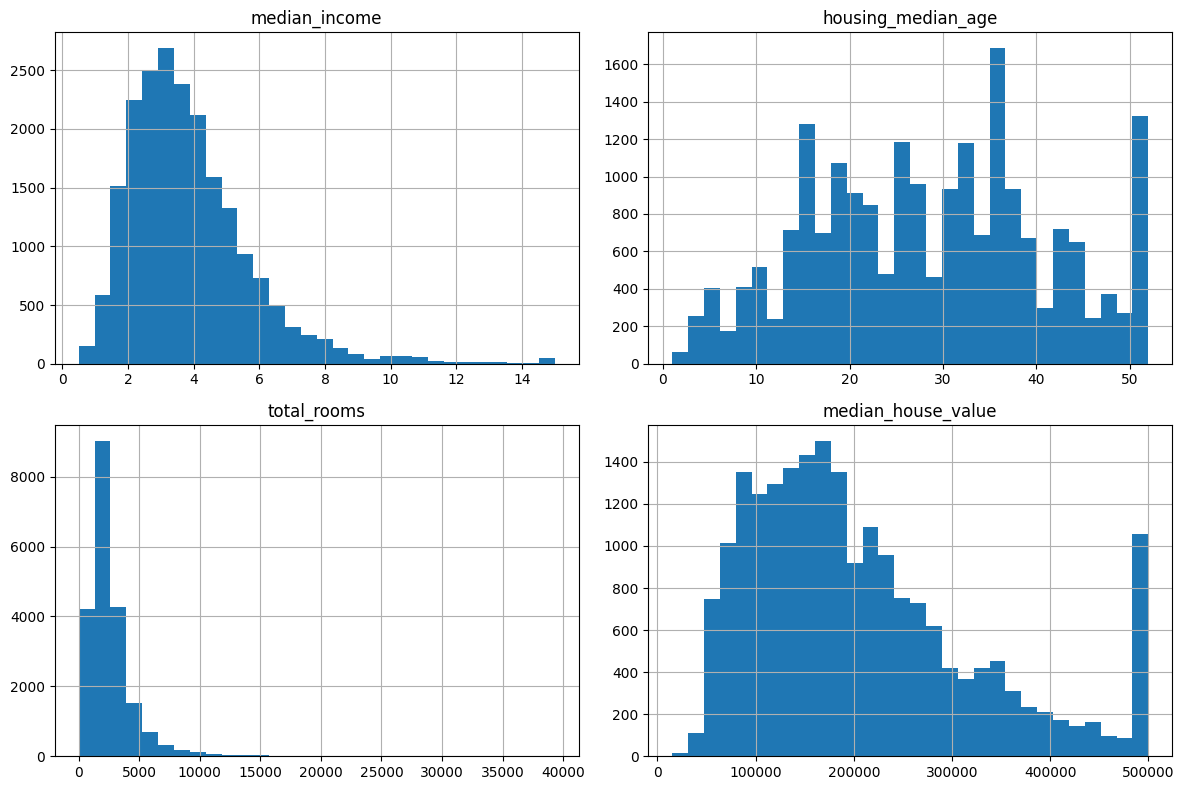

In [40]:
import matplotlib.pyplot as plt

# Create histograms
df[['median_income', 'housing_median_age',
    'total_rooms', 'median_house_value']].hist(
    bins=30, figsize=(12, 8)
)

plt.tight_layout()
plt.show()

# **Histogram Analysis**

Histograms were generated for median income, housing median age, total rooms, and median house value.

Median income and total rooms exhibited right-skewed distributions, indicating that most housing districts had relatively lower values, while a smaller number had unusually high values. Housing median age showed a wider distribution, with a noticeable concentration at 52 years. Median house values were primarily concentrated between $100,000 and $300,000, with a spike near $500,000, suggesting an upper limit on recorded values.

# **Scatterplot**

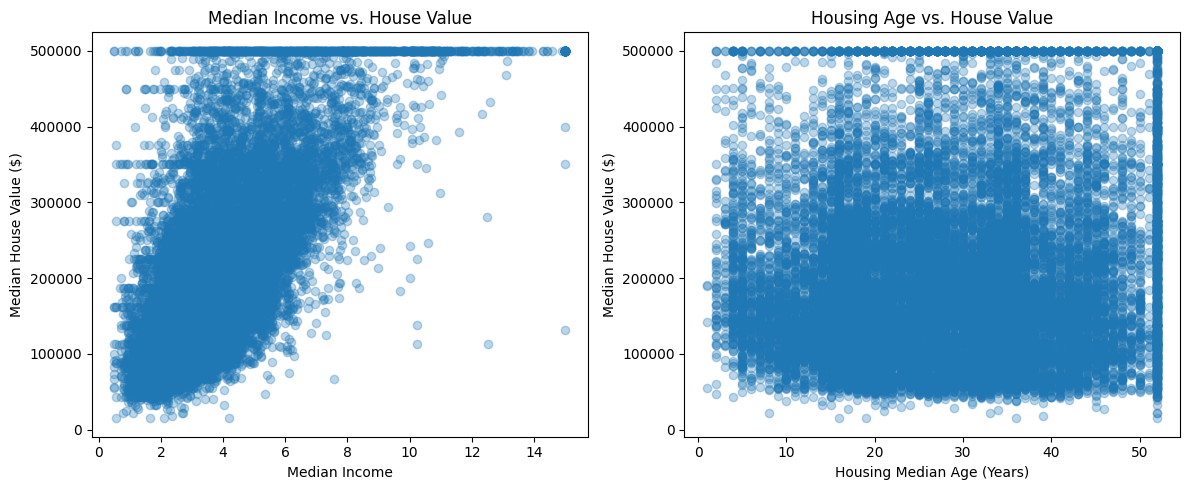

In [41]:


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Median income vs. house value
axes[0].scatter(
    df['median_income'],
    df['median_house_value'],
    alpha=0.3
)
axes[0].set_title('Median Income vs. House Value')
axes[0].set_xlabel('Median Income')
axes[0].set_ylabel('Median House Value ($)')

# Housing age vs. house value
axes[1].scatter(
    df['housing_median_age'],
    df['median_house_value'],
    alpha=0.3
)
axes[1].set_title('Housing Age vs. House Value')
axes[1].set_xlabel('Housing Median Age (Years)')
axes[1].set_ylabel('Median House Value ($)')

plt.tight_layout()
plt.show()

# **Scatter Plot Analysis**
Scatter plots were used to examine the relationships between median income, housing median age, and median house value.

Median income showed a clear positive relationship with median house value, indicating that higher-income districts generally had higher housing values. In contrast, housing median age showed a weaker relationship, with house values varying considerably across different housing ages.

These findings suggest that median income may be a more useful predictor of house values than housing age alone.

# **Boxplot**


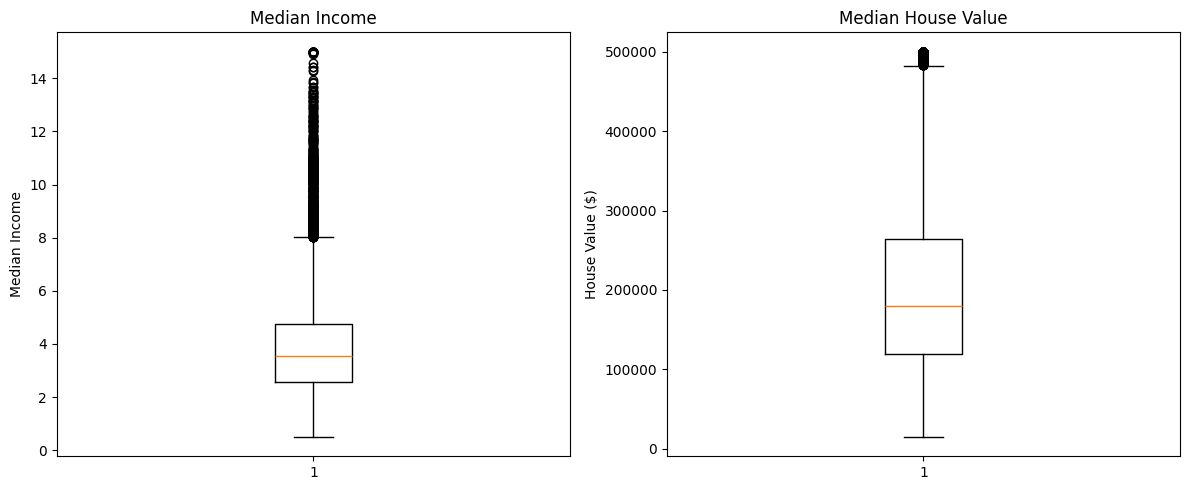

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot
axes[0].boxplot(df['median_income'])
axes[0].set_title('Median Income')
axes[0].set_ylabel('Median Income')

# Box plot for median house value
axes[1].boxplot(df['median_house_value'])
axes[1].set_title('Median House Value')
axes[1].set_ylabel('House Value ($)')

plt.tight_layout()
plt.show()

# **Box Plot Analysis**

Box plots were generated to examine the distributions of median income and median house value and identify potential outliers.

Median income had a median of approximately 3.53, with several high-value observations above the upper whisker. Median house value had a median of $179,700, with potential outliers extending to $500,001.

Both variables exhibited right-skewed distributions. These observations suggest that extreme values and upper limits in the dataset may influence model predictions.

# **EDA Summary**

Overall, the exploratory analysis identified median income as a potentially important predictor of median house value. The visualizations also revealed skewed distributions, potential outliers, and upper limits in housing age and house values. These findings provided a foundation for the subsequent statistical analysis and machine learning models.

# **4 Statistical Analysis**

Statistical analysis was conducted to examine relationships between housing characteristics and median house values. Pearson correlation analysis and simple linear regression were used to identify important predictors and evaluate their statistical relationships with housing prices.

# **Pearson Correlation Analysis**

In [43]:
# Select variables
variables = [
    'median_income',
    'housing_median_age',
    'total_rooms',
    'median_house_value'
]

# Calculate Pearson correlation
correlation_matrix = df[variables].corr()


print(correlation_matrix.round(3))

                    median_income  housing_median_age  total_rooms  \
median_income               1.000              -0.119        0.198   
housing_median_age         -0.119               1.000       -0.361   
total_rooms                 0.198              -0.361        1.000   
median_house_value          0.688               0.106        0.134   

                    median_house_value  
median_income                    0.688  
housing_median_age               0.106  
total_rooms                      0.134  
median_house_value               1.000  


# **Pearson Correlation Analysis**

Pearson correlation analysis was performed to examine the relationships between median_income, housing_median_age, total_rooms, and median_house_value.

Median income demonstrated the strongest positive correlation with median house value (r = 0.688), indicating that higher-income housing districts generally had higher house values.

Housing median age showed a very weak positive correlation with median house value (r = 0.106), while total rooms showed a weak positive correlation (r = 0.134). Additionally, housing median age and total rooms were negatively correlated (r = -0.361), suggesting that older housing districts tended to have fewer total rooms.

Overall, median income demonstrated the strongest linear relationship with median house value among the variables examined.

# **Simple Linear Regression**

In [44]:
import statsmodels.api as sm

# Vaiables
X = df[['median_income']]
y = df['median_house_value']

# intercept
X = sm.add_constant(X)

#  linear regression model
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                 1.856e+04
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:33:44   Log-Likelihood:            -2.6325e+05
No. Observations:               20640   AIC:                         5.265e+05
Df Residuals:                   20638   BIC:                         5.265e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          4.509e+04   1322.872     34.082

In [45]:
print("Current dataset shape:", df.shape)
print("Missing income values:", df['median_income'].isna().sum())
print("Missing house values:", df['median_house_value'].isna().sum())

Current dataset shape: (20640, 10)
Missing income values: 0
Missing house values: 0


# **Simple Linear Regression Analysis**

Simple linear regression was performed using median income as the independent variable and median house value as the dependent variable.

The regression model used 20,640 observations and produced an R-squared value of 0.473, indicating that median income explained approximately 47.3% of the variation in median house values.

The regression coefficient for median income was approximately 41,790, suggesting that each one-unit increase in median income was associated with an estimated $41,790 increase in median house value.

The relationship was statistically significant (p < 0.001), providing evidence of a positive linear association between median income and median house value.

# **Statistical Analysis Summary**

Both statistical techniques identified median income as an important variable associated with housing prices. The correlation analysis demonstrated a moderately strong positive relationship, while simple linear regression showed that median income explained a substantial portion of the variation in house values.

However, approximately 52.7% of the variation remained unexplained by the simple regression model. This suggests that additional housing characteristics and geographic factors may improve predictive performance.

# **5. Machine Learning Models**

Two machine learning models, Linear Regression and Random Forest Regression, were developed to predict median house values using housing characteristics from the California Housing Prices dataset. Both models were trained using the same training dataset and evaluated on the same testing dataset to allow for a consistent comparison.

In [46]:
# original dataset
# Using df since df_original is not defined
df = df.copy()

# Define  (X) and (y)
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']


print("Features:", X.shape)
print("Target:", y.shape)

Features: (20640, 9)
Target: (20640,)


In [47]:
from sklearn.model_selection import train_test_split

# Split 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

#  dimensions
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 9)
X_test: (4128, 9)
y_train: (16512,)
y_test: (4128,)


In [48]:
from sklearn.impute import SimpleImputer

# median imputer
imputer = SimpleImputer(strategy='median')

# Fit the imputertraining data only
X_train['total_bedrooms'] = imputer.fit_transform(
    X_train[['total_bedrooms']]
).ravel()

#  imputer to testing data
X_test['total_bedrooms'] = imputer.transform(
    X_test[['total_bedrooms']]
).ravel()

# missing values
print("Training missing values:")
print(X_train.isnull().sum())

print("\nTesting missing values:")
print(X_test.isnull().sum())

Training missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

Testing missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64


In [49]:
from sklearn.preprocessing import OneHotEncoder

#  encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

#  categories  training data
train_encoded = encoder.fit_transform(
    X_train[['ocean_proximity']]
)

#  encoding to the testing data
test_encoded = encoder.transform(
    X_test[['ocean_proximity']]
)

# categories
print("Ocean proximity categories:")
print(encoder.categories_)

Ocean proximity categories:
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [50]:
# encoded columns
encoded_columns = encoder.get_feature_names_out(['ocean_proximity'])

#convert  into DataFrames
train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

# Remove the original categories
X_train = pd.concat(
    [X_train.drop(columns=['ocean_proximity']), train_encoded_df],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=['ocean_proximity']), test_encoded_df],
    axis=1
)

# Check the updated datasets
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nColumns:")
print(X_train.columns.tolist())

Training shape: (16512, 13)
Testing shape: (4128, 13)

Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


# **Linear Regression Model**

Multiple Linear Regression was selected as the first predictive model because it provides a straightforward approach to examining linear relationships between housing characteristics and median house values.

The model was trained using 16,512 observations and 13 numerical predictor features, including median income, housing age, geographic coordinates, and encoded ocean proximity categories.

The LinearRegression() model from scikit-learn was implemented using its default hyperparameters. After training, the model generated predictions for the 4,128 observations in the testing dataset.

In [51]:
from sklearn.linear_model import LinearRegression

# Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict house values using the testing data
lr_predictions = lr_model.predict(X_test)

# Display the first five predictions
print("First five predicted house values:")
print(lr_predictions[:5])

print("\nFirst five actual house values:")
print(y_test.iloc[:5].values)

First five predicted house values:
[ 54261.02768975 124430.91772797 255694.95828245 268208.01035997
 262975.01360647]

First five actual house values:
[ 47700.  45800. 500001. 218600. 278000.]


# **Random Forest Regression Model**

Random Forest Regression was selected as the second model because it can capture nonlinear relationships and interactions between housing characteristics that may not be represented by Linear Regression.

The model was implemented using scikit-learn's RandomForestRegressor() with the following hyperparameters:

n_estimators=100: Specifies that the forest contains 100 decision trees.

random_state=42: Ensures reproducibility.

n_jobs=-1: Uses all available CPU cores for parallel processing.

Other hyperparameters were left at their default settings.

The Random Forest model was trained using the same 16,512 training observations and 13 predictor features. Predictions were then generated for the same 4,128 testing observations used by Linear Regression.

In [52]:
from sklearn.ensemble import RandomForestRegressor

#  Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Display the first five predictions
print("First five predicted house values:")
print(rf_predictions[:5])

print("\nFirst five actual house values:")
print(y_test.iloc[:5].values)

First five predicted house values:
[ 51744.    71115.   461228.37 255273.   268203.  ]

First five actual house values:
[ 47700.  45800. 500001. 218600. 278000.]


# **Model Training Summary**

Both models were trained using an 80/20 training and testing split. Missing bedroom values were handled through median imputation, and ocean proximity categories were converted into numerical features using one-hot encoding.

Linear Regression was used to establish a baseline predictive mode, while Random Forest was used to explore whether capturing more complex relationships could improve prediction accuracy.

Both models successfully generated predictions for the testing dataset, which were subsequently evaluated using MAE, RMSE, and R².

# **6. Model Performance Evaluation**

The performance of the Linear Regression and Random Forest Regression models was evaluated using three metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²). Both models were evaluated using the same testing dataset containing 4,128 observations.

# **Evaluation Metrics**

Mean Absolute Error (MAE) measures the average absolute difference between predicted and actual house values. Lower MAE values indicate more accurate predictions.

Root Mean Squared Error (RMSE) measures prediction error while placing greater emphasis on larger errors. Lower RMSE values indicate better model performance.

R-squared (R²) measures the proportion of variation in median house values explained by the model. Higher R² values indicate better predictive performance.

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Display results
print("Linear Regression Performance:")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("R²:", round(lr_r2, 3))

print("\nRandom Forest Performance:")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 3))

Linear Regression Performance:
MAE: 50670.49
RMSE: 70059.19
R²: 0.625

Random Forest Performance:
MAE: 31636.35
RMSE: 48977.06
R²: 0.817


# **Model Performance Results**

Random Forest Regression outperformed Linear Regression across all three evaluation metrics.

The Random Forest model achieved an MAE of approximately $31,636, compared with $50,670 for Linear Regression, representing a reduction in average absolute prediction error of approximately 37.6%.

Random Forest also achieved a lower RMSE of approximately $48,977 compared with $70,059 for Linear Regression, indicating fewer or smaller large prediction errors overall.

The R² value increased from 0.625 for Linear Regression to 0.817 for Random Forest, indicating that Random Forest explained approximately 81.7% of the variation in median house values in the testing dataset.

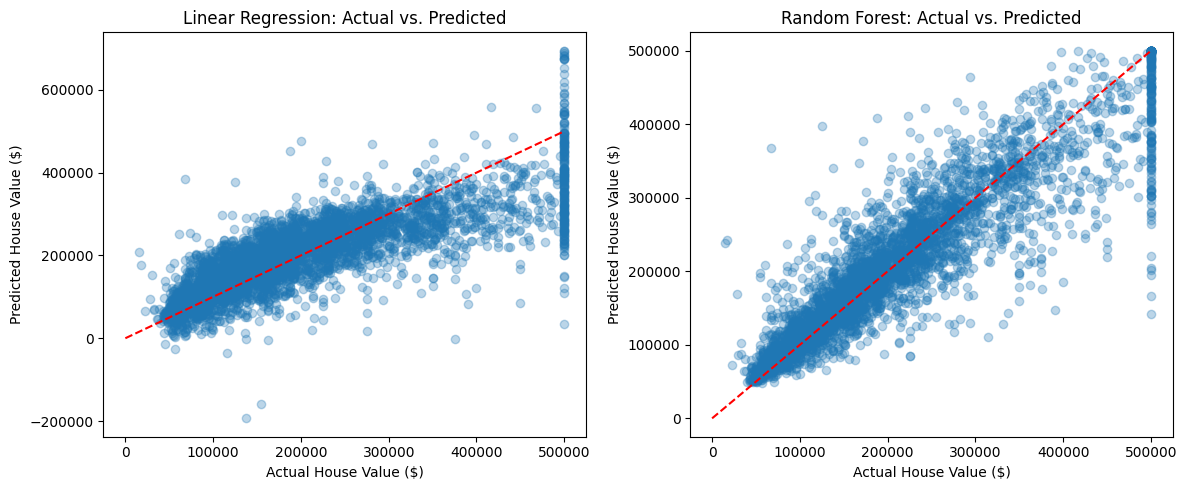

In [54]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Linear Regression
axes[0].scatter(y_test, lr_predictions, alpha=0.3)
axes[0].plot([0, 500000], [0, 500000], 'r--')
axes[0].set_title('Linear Regression: Actual vs. Predicted')
axes[0].set_xlabel('Actual House Value ($)')
axes[0].set_ylabel('Predicted House Value ($)')

# Random Forest
axes[1].scatter(y_test, rf_predictions, alpha=0.3)
axes[1].plot([0, 500000], [0, 500000], 'r--')
axes[1].set_title('Random Forest: Actual vs. Predicted')
axes[1].set_xlabel('Actual House Value ($)')
axes[1].set_ylabel('Predicted House Value ($)')

plt.tight_layout()
plt.show()

# **Actual vs. Predicted Values**

Scatter plots comparing actual and predicted median house values were generated for both models.

The Linear Regression plot showed greater dispersion around the reference line, indicating larger differences between predicted and actual values. The model also tended to underestimate some higher-value housing districts.

The Random Forest plot showed predictions more closely concentrated around the reference line, suggesting improved predictive accuracy. However, some prediction errors remained, particularly for higher-value housing districts.

These visualizations supported the numerical evaluation results, demonstrating that Random Forest produced more accurate predictions than Linear Regression.

# **Model Comparison Summary**

Overall, Random Forest Regression was the better-performing model for predicting median house values in this dataset. Its ability to capture nonlinear relationships and interactions between housing characteristics likely contributed to its improved performance.

Although Linear Regression provided a useful baseline, Random Forest achieved lower prediction errors and a higher R² value, making it the preferred model based on the testing results.

# **7. Conclusion and Future Work**

# **Conclusion**

This project examined the California Housing Prices dataset using exploratory data analysis, statistical analysis, and machine learning to investigate factors associated with median house values.

The exploratory and statistical analyses identified median income as an important predictor of housing prices. Simple linear regression showed that median income explained approximately 47.3% of the variation in median house values.

Two machine learning models, Linear Regression and Random Forest Regression, were developed and evaluated. Random Forest achieved the best predictive performance, with an MAE of $31,636.35, an RMSE of $48,977.06, and an R² of 0.817. These results demonstrated that Random Forest was more effective at predicting median house values than Linear Regression on the testing dataset.

Overall, the findings suggest that combining multiple housing characteristics and using models capable of capturing nonlinear relationships can improve housing price predictions.

# **Limitations**

The dataset contained an upper limit of $500,001 for median house values, which may have affected predictions for higher-priced housing districts. Additionally, the analysis was limited to the variables available in the dataset, and model performance was evaluated using a single training and testing split.

# **Future Work**

Future research could explore additional housing and neighborhood characteristics, including access to schools, employment opportunities, and local amenities. Hyperparameter tuning and cross-validation could also be used to improve model performance and evaluate its stability across different data splits.

Further analysis could investigate the effect of the housing value cap and explore alternative regression models to improve predictions for higher-value housing districts.